# 이상탐지

## Z-score와 IRQ

전체 데이터 개수: 105
Z-Score 이상치 개수: 5
IQR 이상치 개수: 5
최종 이상치 개수: 5

전체 결과
     feature1  feature2  feature3  zscore_outlier  iqr_outlier  is_outlier
0    1.764052  0.400157  0.978738           False        False       False
1    2.240893  1.867558 -0.977278           False        False       False
2    0.950088 -0.151357 -0.103219           False        False       False
3    0.410599  0.144044  1.454274           False        False       False
4    0.761038  0.121675  0.443863           False        False       False
..        ...       ...       ...             ...          ...         ...
100  1.546781 -1.218789 -5.247445            True         True        True
101 -0.911613 -2.895791  4.188460            True         True        True
102 -5.600344  5.507793 -1.735574            True         True        True
103 -1.719517 -5.804058 -3.777212            True         True        True
104 -1.184886  5.151497 -4.804621            True         True        True

[105 rows x 6 columns]

최종 이상치
 

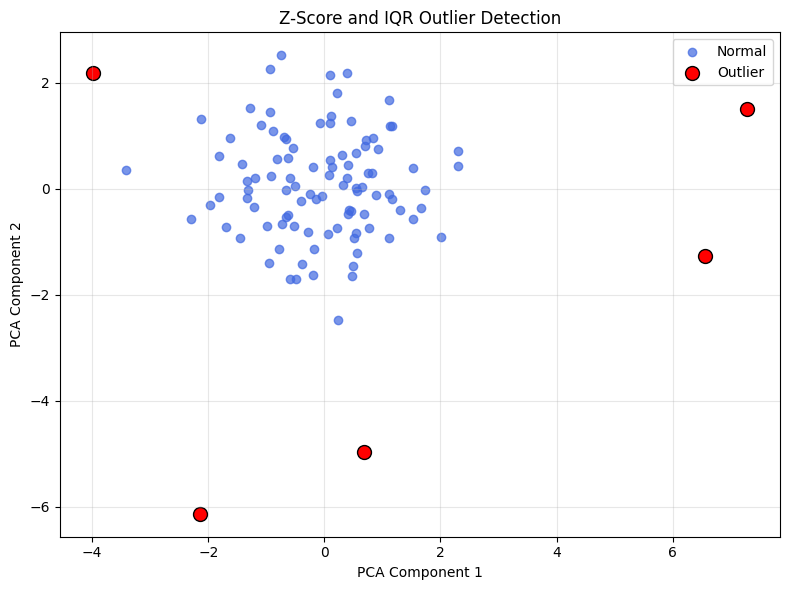

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.stats import zscore
from sklearn.decomposition import PCA


# =========================================================
# 1. 예제 데이터 생성
# =========================================================
np.random.seed(0)

# 정상 데이터 100개, 변수 3개
normal_data = np.random.normal(size=(100, 3))

# 임의의 이상치 후보 5개
outlier_data = np.random.uniform(
    low=-6,
    high=6,
    size=(5, 3)
)

# 정상 데이터와 이상치 후보 결합
data = np.vstack([normal_data, outlier_data])

feature_columns = [
    "feature1",
    "feature2",
    "feature3"
]

df = pd.DataFrame(
    data,
    columns=feature_columns
)


# =========================================================
# 2. Z-Score 기반 이상치 탐지
# =========================================================
z_threshold = 3

zscore_columns = []

for column in feature_columns:
    zscore_column = f"zscore_{column}"

    # 변수별 Z-Score 계산
    df[zscore_column] = zscore(df[column])

    zscore_columns.append(zscore_column)


# 변수 중 하나라도 Z-Score 절댓값이 임계값보다 크면 이상치
df["zscore_outlier"] = (
    df[zscore_columns]
    .abs()
    .gt(z_threshold)
    .any(axis=1)
)


# =========================================================
# 3. IQR 기반 이상치 탐지 함수
# =========================================================
def detect_outliers_iqr(dataframe, columns, multiplier=1.5):
    """
    각 변수의 IQR 범위를 계산하여 이상치 여부를 반환합니다.

    Parameters
    ----------
    dataframe : pandas.DataFrame
        분석할 데이터프레임
    columns : list
        이상치를 탐지할 변수 목록
    multiplier : float
        IQR 범위 계산에 사용할 배수
    """
    iqr_outlier_columns = []

    for column in columns:
        # 제1사분위수와 제3사분위수 계산
        q1 = dataframe[column].quantile(0.25)
        q3 = dataframe[column].quantile(0.75)

        # IQR 계산
        iqr = q3 - q1

        # 정상 범위의 하한과 상한 계산
        lower_bound = q1 - (multiplier * iqr)
        upper_bound = q3 + (multiplier * iqr)

        # 변수별 이상치 여부 저장
        outlier_column = f"iqr_outlier_{column}"

        dataframe[outlier_column] = (
            (dataframe[column] < lower_bound)
            | (dataframe[column] > upper_bound)
        )

        iqr_outlier_columns.append(outlier_column)

    # 변수 중 하나라도 IQR 범위를 벗어나면 이상치
    dataframe["iqr_outlier"] = (
        dataframe[iqr_outlier_columns]
        .any(axis=1)
    )


# =========================================================
# 4. IQR 기반 이상치 탐지 실행
# =========================================================
detect_outliers_iqr(
    dataframe=df,
    columns=feature_columns,
    multiplier=1.5
)


# =========================================================
# 5. 최종 이상치 판정
# Z-Score 또는 IQR 중 하나에서 탐지되면 이상치
# =========================================================
df["is_outlier"] = (
    df["zscore_outlier"]
    | df["iqr_outlier"]
)


# =========================================================
# 6. 결과 출력
# =========================================================
result_columns = [
    "feature1",
    "feature2",
    "feature3",
    "zscore_outlier",
    "iqr_outlier",
    "is_outlier"
]

print(f"전체 데이터 개수: {len(df)}")
print(f"Z-Score 이상치 개수: {df['zscore_outlier'].sum()}")
print(f"IQR 이상치 개수: {df['iqr_outlier'].sum()}")
print(f"최종 이상치 개수: {df['is_outlier'].sum()}")

print("\n전체 결과")
print(df[result_columns])

print("\n최종 이상치")
print(df.loc[df["is_outlier"], result_columns])


# =========================================================
# 7. PCA를 이용한 2차원 변환
# =========================================================
pca = PCA(n_components=2)

data_2d = pca.fit_transform(
    df[feature_columns]
)


# =========================================================
# 8. 이상치 탐지 결과 시각화
# =========================================================
normal_mask = ~df["is_outlier"]
outlier_mask = df["is_outlier"]

plt.figure(figsize=(8, 6))

# 정상 데이터
plt.scatter(
    data_2d[normal_mask, 0],
    data_2d[normal_mask, 1],
    color="royalblue",
    alpha=0.7,
    label="Normal"
)

# 이상치 데이터
plt.scatter(
    data_2d[outlier_mask, 0],
    data_2d[outlier_mask, 1],
    color="red",
    edgecolor="black",
    s=100,
    label="Outlier"
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Z-Score and IQR Outlier Detection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Mahalanobis 거리 (MD)

이상치 판정 임계값: 4.2667
탐지된 이상치 개수: 4

전체 결과
     feature1  feature2  feature3  mahalanobis_distance  is_outlier
0    1.764052  0.400157  0.978738              1.747353       False
1    2.240893  1.867558 -0.977278              2.610957       False
2    0.950088 -0.151357 -0.103219              0.787408       False
3    0.410599  0.144044  1.454274              1.314033       False
4    0.761038  0.121675  0.443863              0.783054       False
..        ...       ...       ...                   ...         ...
100  1.546781 -1.218789 -5.247445              4.376988        True
101 -0.911613 -2.895791  4.188460              4.174511       False
102 -5.600344  5.507793 -1.735574              5.664640        True
103 -1.719517 -5.804058 -3.777212              5.713623        True
104 -1.184886  5.151497 -4.804621              4.835571        True

[105 rows x 5 columns]

탐지된 이상치
     feature1  feature2  feature3  mahalanobis_distance  is_outlier
100  1.546781 -1.218789 -5.247445          

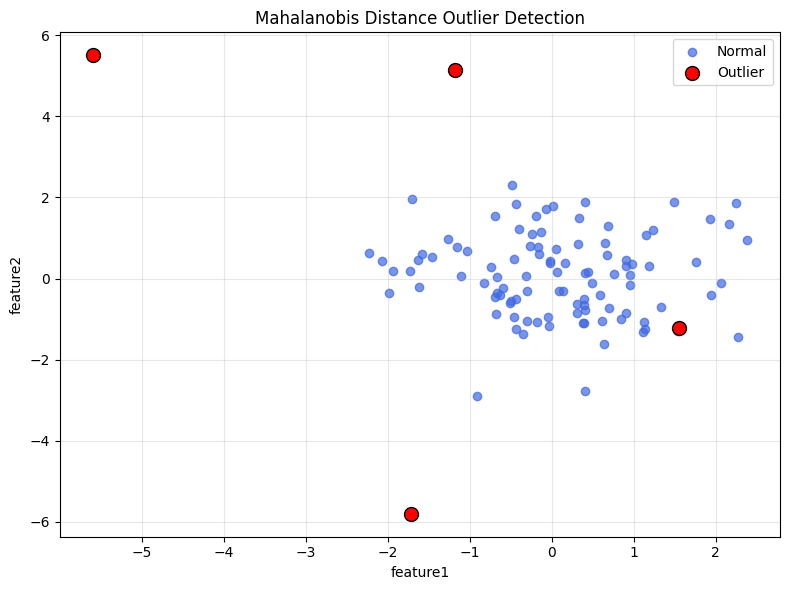

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import inv
from scipy.spatial.distance import mahalanobis


# =========================================================
# 1. 예제 데이터 생성
# =========================================================
np.random.seed(0)

# 정상 데이터 100개, 변수 3개
normal_data = np.random.normal(size=(100, 3))

# 임의의 이상치 5개
outlier_data = np.random.uniform(
    low=-6,
    high=6,
    size=(5, 3)
)

# 정상 데이터와 이상치 결합
data = np.vstack([normal_data, outlier_data])

df = pd.DataFrame(
    data,
    columns=["feature1", "feature2", "feature3"]
)


# =========================================================
# 2. 평균과 공분산 역행렬 계산
# =========================================================
feature_columns = ["feature1", "feature2", "feature3"]

mean_vector = df[feature_columns].mean().values
cov_matrix = np.cov(df[feature_columns].values, rowvar=False)
inv_cov_matrix = inv(cov_matrix)


# =========================================================
# 3. 마할라노비스 거리 계산
# =========================================================
def calculate_mahalanobis_distance(row):
    """하나의 데이터와 전체 데이터 평균 사이의 마할라노비스 거리"""
    return mahalanobis(
        row[feature_columns].values,
        mean_vector,
        inv_cov_matrix
    )


df["mahalanobis_distance"] = df.apply(
    calculate_mahalanobis_distance,
    axis=1
)


# =========================================================
# 4. 이상치 탐지
# 기준: 마할라노비스 거리 평균 + 표준편차의 3배
# =========================================================
distance_mean = df["mahalanobis_distance"].mean()
distance_std = df["mahalanobis_distance"].std()

threshold = distance_mean + (3 * distance_std)

df["is_outlier"] = (
    df["mahalanobis_distance"] > threshold
)


# =========================================================
# 5. 결과 출력
# =========================================================
print(f"이상치 판정 임계값: {threshold:.4f}")
print(f"탐지된 이상치 개수: {df['is_outlier'].sum()}")

print("\n전체 결과")
print(df)

print("\n탐지된 이상치")
print(df[df["is_outlier"]])


# =========================================================
# 6. 결과 시각화
# =========================================================
normal_points = df[~df["is_outlier"]]
outlier_points = df[df["is_outlier"]]

plt.figure(figsize=(8, 6))

plt.scatter(
    normal_points["feature1"],
    normal_points["feature2"],
    color="royalblue",
    alpha=0.7,
    label="Normal"
)

plt.scatter(
    outlier_points["feature1"],
    outlier_points["feature2"],
    color="red",
    edgecolor="black",
    s=100,
    label="Outlier"
)

plt.xlabel("feature1")
plt.ylabel("feature2")
plt.title("Mahalanobis Distance Outlier Detection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## LOF

전체 데이터 개수: 105
정상 데이터 개수: 99
탐지된 이상치 개수: 6

전체 결과
     feature1  feature2  feature3  lof_score  anomaly_score  lof_prediction  \
0    1.764052  0.400157  0.978738  -1.148370       1.148370               1   
1    2.240893  1.867558 -0.977278  -1.427434       1.427434               1   
2    0.950088 -0.151357 -0.103219  -0.975190       0.975190               1   
3    0.410599  0.144044  1.454274  -1.050692       1.050692               1   
4    0.761038  0.121675  0.443863  -0.962164       0.962164               1   
..        ...       ...       ...        ...            ...             ...   
100  1.546781 -1.218789 -5.247445  -2.845791       2.845791              -1   
101 -0.911613 -2.895791  4.188460  -2.921311       2.921311              -1   
102 -5.600344  5.507793 -1.735574  -4.029115       4.029115              -1   
103 -1.719517 -5.804058 -3.777212  -3.968806       3.968806              -1   
104 -1.184886  5.151497 -4.804621  -3.522054       3.522054              -1   

 

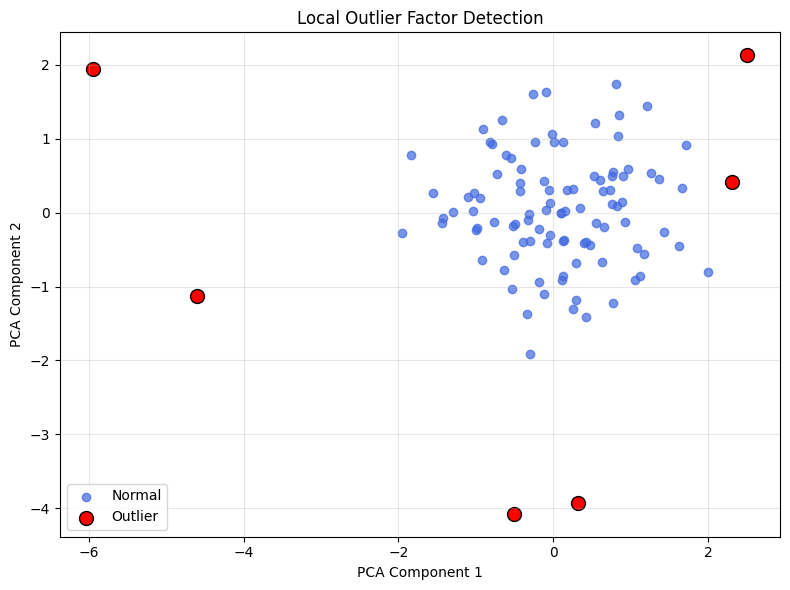

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


# =========================================================
# 1. 예제 데이터 생성
# =========================================================
np.random.seed(0)

# 정상 데이터 100개, 변수 3개
normal_data = np.random.normal(size=(100, 3))

# 임의의 이상치 후보 5개
outlier_data = np.random.uniform(
    low=-6,
    high=6,
    size=(5, 3)
)

# 정상 데이터와 이상치 후보 결합
data = np.vstack([normal_data, outlier_data])

feature_columns = [
    "feature1",
    "feature2",
    "feature3"
]

df = pd.DataFrame(
    data,
    columns=feature_columns
)


# =========================================================
# 2. 변수 표준화
# =========================================================
scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    df[feature_columns]
)


# =========================================================
# 3. LOF 모델 생성
# =========================================================
model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=0.05,
    metric="minkowski",
    p=2
)


# =========================================================
# 4. 모델 학습 및 이상치 탐지
# =========================================================
prediction = model.fit_predict(
    scaled_data
)

# LOF의 원래 예측 결과 저장
#  1: 정상
# -1: 이상치
df["lof_prediction"] = prediction


# =========================================================
# 5. 이상치 여부 변환
# 정상: False, 이상치: True
# =========================================================
df["is_outlier"] = (
    df["lof_prediction"] == -1
)


# =========================================================
# 6. LOF 점수 저장
# 값이 작을수록 이상치 가능성이 큼
# =========================================================
df["lof_score"] = model.negative_outlier_factor_


# 해석이 쉬운 양수 형태의 이상치 점수
# 값이 클수록 이상치 가능성이 큼
df["anomaly_score"] = (
    -model.negative_outlier_factor_
)


# =========================================================
# 7. 결과 출력
# =========================================================
result_columns = [
    "feature1",
    "feature2",
    "feature3",
    "lof_score",
    "anomaly_score",
    "lof_prediction",
    "is_outlier"
]

print(f"전체 데이터 개수: {len(df)}")
print(f"정상 데이터 개수: {(~df['is_outlier']).sum()}")
print(f"탐지된 이상치 개수: {df['is_outlier'].sum()}")

print("\n전체 결과")
print(df[result_columns])

print("\n탐지된 이상치")
print(
    df.loc[df["is_outlier"], result_columns]
    .sort_values(
        "anomaly_score",
        ascending=False
    )
)


# =========================================================
# 8. PCA를 이용한 2차원 변환
# 표준화된 데이터를 2차원으로 축소
# =========================================================
pca = PCA(n_components=2)

data_2d = pca.fit_transform(
    scaled_data
)


# =========================================================
# 9. 이상치 탐지 결과 시각화
# =========================================================
normal_mask = ~df["is_outlier"]
outlier_mask = df["is_outlier"]

plt.figure(figsize=(8, 6))

# 정상 데이터
plt.scatter(
    data_2d[normal_mask, 0],
    data_2d[normal_mask, 1],
    color="royalblue",
    alpha=0.7,
    label="Normal"
)

# 이상치 데이터
plt.scatter(
    data_2d[outlier_mask, 0],
    data_2d[outlier_mask, 1],
    color="red",
    edgecolor="black",
    s=100,
    label="Outlier"
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Local Outlier Factor Detection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## One-Class SVM 기반 이상치 탐지

전체 데이터 개수: 105
정상 데이터 개수: 97
탐지된 이상치 개수: 8

전체 결과
     feature1  feature2  feature3  anomaly_score  ocsvm_prediction  is_outlier
0    1.764052  0.400157  0.978738       0.104481                 1       False
1    2.240893  1.867558 -0.977278       0.000157                 1       False
2    0.950088 -0.151357 -0.103219       0.124300                 1       False
3    0.410599  0.144044  1.454274       0.093504                 1       False
4    0.761038  0.121675  0.443863       0.131053                 1       False
..        ...       ...       ...            ...               ...         ...
100  1.546781 -1.218789 -5.247445       0.000455                 1       False
101 -0.911613 -2.895791  4.188460       0.000343                 1       False
102 -5.600344  5.507793 -1.735574       0.000297                 1       False
103 -1.719517 -5.804058 -3.777212       0.000291                 1       False
104 -1.184886  5.151497 -4.804621       0.000457                 1       False

[

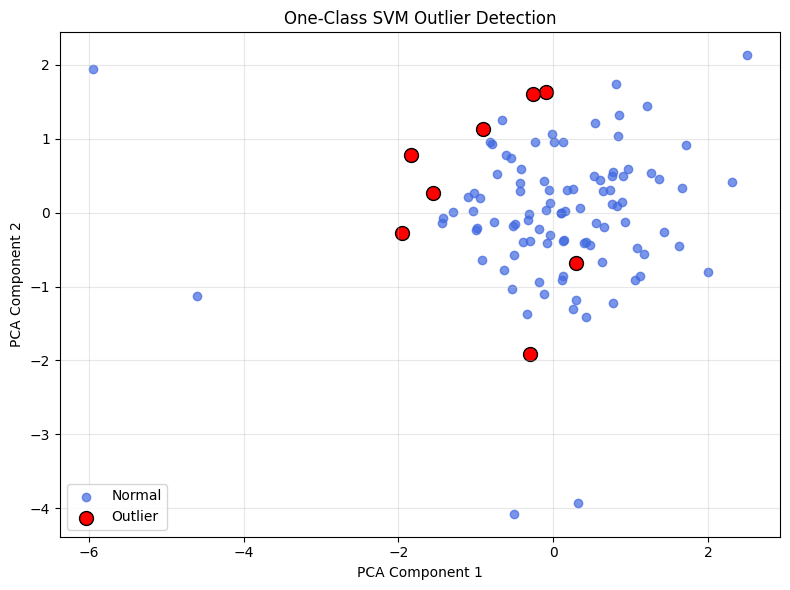

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA


# =========================================================
# 1. 예제 데이터 생성
# =========================================================
np.random.seed(0)

# 정상 데이터 100개, 변수 3개
normal_data = np.random.normal(size=(100, 3))

# 임의의 이상치 후보 5개
outlier_data = np.random.uniform(
    low=-6,
    high=6,
    size=(5, 3)
)

# 정상 데이터와 이상치 후보 결합
data = np.vstack([normal_data, outlier_data])

feature_columns = [
    "feature1",
    "feature2",
    "feature3"
]

df = pd.DataFrame(
    data,
    columns=feature_columns
)


# =========================================================
# 2. 변수 표준화
# =========================================================
scaler = StandardScaler()

scaled_data = scaler.fit_transform(
    df[feature_columns]
)


# =========================================================
# 3. One-Class SVM 모델 생성
# =========================================================
model = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=0.05
)


# =========================================================
# 4. 모델 학습 및 이상치 탐지
# =========================================================
prediction = model.fit_predict(
    scaled_data
)

# One-Class SVM의 원래 예측 결과 저장
#  1: 정상
# -1: 이상치
df["ocsvm_prediction"] = prediction


# =========================================================
# 5. 이상치 여부 변환
# 정상: False, 이상치: True
# =========================================================
df["is_outlier"] = (
    df["ocsvm_prediction"] == -1
)


# =========================================================
# 6. 이상치 점수 계산
# 값이 작을수록 이상치 가능성이 큼
# =========================================================
df["anomaly_score"] = model.decision_function(
    scaled_data
)


# =========================================================
# 7. 결과 출력
# =========================================================
result_columns = [
    "feature1",
    "feature2",
    "feature3",
    "anomaly_score",
    "ocsvm_prediction",
    "is_outlier"
]

print(f"전체 데이터 개수: {len(df)}")
print(f"정상 데이터 개수: {(~df['is_outlier']).sum()}")
print(f"탐지된 이상치 개수: {df['is_outlier'].sum()}")

print("\n전체 결과")
print(df[result_columns])

print("\n탐지된 이상치")
print(
    df.loc[df["is_outlier"], result_columns]
    .sort_values("anomaly_score")
)


# =========================================================
# 8. PCA를 이용한 2차원 변환
# 표준화된 데이터를 2차원으로 축소
# =========================================================
pca = PCA(n_components=2)

data_2d = pca.fit_transform(
    scaled_data
)


# =========================================================
# 9. 이상치 탐지 결과 시각화
# =========================================================
normal_mask = ~df["is_outlier"]
outlier_mask = df["is_outlier"]

plt.figure(figsize=(8, 6))

# 정상 데이터
plt.scatter(
    data_2d[normal_mask, 0],
    data_2d[normal_mask, 1],
    color="royalblue",
    alpha=0.7,
    label="Normal"
)

# 이상치 데이터
plt.scatter(
    data_2d[outlier_mask, 0],
    data_2d[outlier_mask, 1],
    color="red",
    edgecolor="black",
    s=100,
    label="Outlier"
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("One-Class SVM Outlier Detection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## Isolation Forest(IF) 기반 이상치 탐지

전체 데이터 개수: 105
정상 데이터 개수: 99
탐지된 이상치 개수: 6

전체 결과
     feature1  feature2  feature3  anomaly_score  if_prediction  is_outlier
0    1.764052  0.400157  0.978738       0.107472              1       False
1    2.240893  1.867558 -0.977278       0.033580              1       False
2    0.950088 -0.151357 -0.103219       0.185346              1       False
3    0.410599  0.144044  1.454274       0.139231              1       False
4    0.761038  0.121675  0.443863       0.182001              1       False
..        ...       ...       ...            ...            ...         ...
100  1.546781 -1.218789 -5.247445      -0.095275             -1        True
101 -0.911613 -2.895791  4.188460      -0.105613             -1        True
102 -5.600344  5.507793 -1.735574      -0.201575             -1        True
103 -1.719517 -5.804058 -3.777212      -0.143670             -1        True
104 -1.184886  5.151497 -4.804621      -0.146515             -1        True

[105 rows x 6 columns]

탐지된 이상치
     

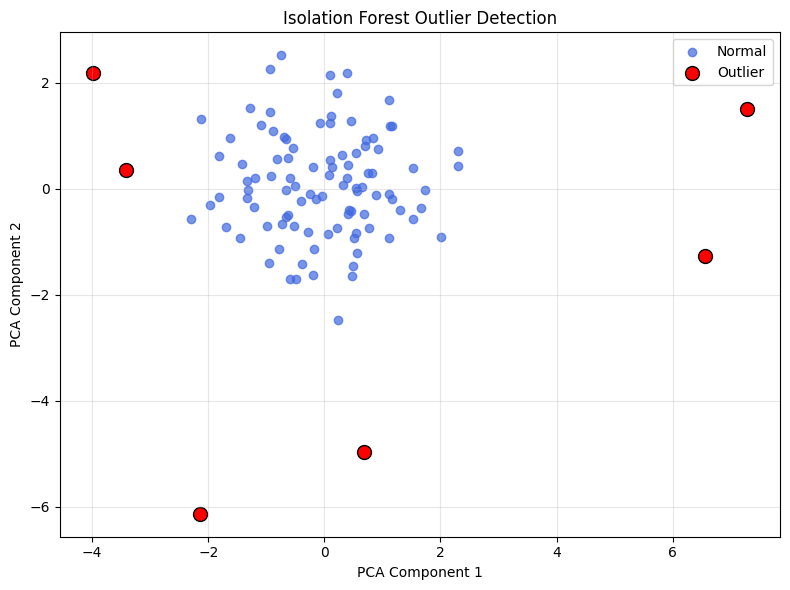

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA


# =========================================================
# 1. 예제 데이터 생성
# =========================================================
np.random.seed(0)

# 정상 데이터 100개, 변수 3개
normal_data = np.random.normal(size=(100, 3))

# 임의의 이상치 후보 5개
outlier_data = np.random.uniform(
    low=-6,
    high=6,
    size=(5, 3)
)

# 정상 데이터와 이상치 후보 결합
data = np.vstack([normal_data, outlier_data])

feature_columns = [
    "feature1",
    "feature2",
    "feature3"
]

df = pd.DataFrame(
    data,
    columns=feature_columns
)


# =========================================================
# 2. Isolation Forest 모델 생성
# =========================================================
model = IsolationForest(
    n_estimators=100,
    contamination=0.05,
    random_state=0
)


# =========================================================
# 3. 모델 학습 및 이상치 탐지
# =========================================================
prediction = model.fit_predict(
    df[feature_columns]
)

# Isolation Forest의 원래 예측 결과 저장
#  1: 정상
# -1: 이상치
df["if_prediction"] = prediction


# =========================================================
# 4. 이상치 여부 변환
# 정상: False, 이상치: True
# =========================================================
df["is_outlier"] = (
    df["if_prediction"] == -1
)


# =========================================================
# 5. 이상치 점수 계산
# 값이 작을수록 이상치 가능성이 큼
# =========================================================
df["anomaly_score"] = model.decision_function(
    df[feature_columns]
)


# =========================================================
# 6. 결과 출력
# =========================================================
result_columns = [
    "feature1",
    "feature2",
    "feature3",
    "anomaly_score",
    "if_prediction",
    "is_outlier"
]

print(f"전체 데이터 개수: {len(df)}")
print(f"정상 데이터 개수: {(~df['is_outlier']).sum()}")
print(f"탐지된 이상치 개수: {df['is_outlier'].sum()}")

print("\n전체 결과")
print(df[result_columns])

print("\n탐지된 이상치")
print(
    df.loc[df["is_outlier"], result_columns]
    .sort_values("anomaly_score")
)


# =========================================================
# 7. PCA를 이용한 2차원 변환
# =========================================================
pca = PCA(n_components=2)

data_2d = pca.fit_transform(
    df[feature_columns]
)


# =========================================================
# 8. 이상치 탐지 결과 시각화
# =========================================================
normal_mask = ~df["is_outlier"]
outlier_mask = df["is_outlier"]

plt.figure(figsize=(8, 6))

# 정상 데이터
plt.scatter(
    data_2d[normal_mask, 0],
    data_2d[normal_mask, 1],
    color="royalblue",
    alpha=0.7,
    label="Normal"
)

# 이상치 데이터
plt.scatter(
    data_2d[outlier_mask, 0],
    data_2d[outlier_mask, 1],
    color="red",
    edgecolor="black",
    s=100,
    label="Outlier"
)

plt.xlabel("PCA Component 1")
plt.ylabel("PCA Component 2")
plt.title("Isolation Forest Outlier Detection")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# **UCI Cardiotocography 데이터셋**

In [ ]:
pip install ucimlrepo

## 데이터 읽기 및 전처리

In [ ]:
import numpy as np
import pandas as pd

from ucimlrepo import fetch_ucirepo
from sklearn.preprocessing import StandardScaler


  # =========================================================
  # 1. UCI Cardiotocography 데이터 불러오기
  # =========================================================
cardiotocography = fetch_ucirepo(id=193)

  # 입력 변수
X = cardiotocography.data.features.copy()

  # 목표 변수
target_data = cardiotocography.data.targets.copy()

print("입력 데이터 크기:", X.shape)
print("목표 변수 목록:", target_data.columns.tolist())

입력 데이터 크기: (2126, 21)
목표 변수 목록: ['CLASS', 'NSP']


In [ ]:
# =========================================================
# 2. NSP 목표 변수 선택
# NSP=1: 정상
# NSP=2: 의심 (제외)
# NSP=3: 병리적 상태 Pathologic (이상)
# =========================================================
y_nsp = target_data["NSP"]

# 정상과 병리적 상태만 선택
selected_mask = y_nsp.isin([1, 3])

X = X.loc[selected_mask].reset_index(drop=True)
y_nsp = y_nsp.loc[selected_mask].reset_index(drop=True)


# =========================================================
# 3. 이상치 정답 생성
# 정상: 0
# 이상치: 1
# =========================================================
y_true = (y_nsp == 3).astype(int)

print(f"전체 데이터 개수: {len(X)}")
print(f"정상 데이터 개수: {(y_true == 0).sum()}")
print(f"실제 이상치 개수: {(y_true == 1).sum()}")
print(f"실제 이상치 비율: {y_true.mean():.4f}")


전체 데이터 개수: 1831
정상 데이터 개수: 1655
실제 이상치 개수: 176
실제 이상치 비율: 0.0961


In [ ]:
# =========================================================
# 4. 결측값 및 데이터 타입 확인
# =========================================================
print("\n데이터 타입")
print(X.dtypes)

print("\n결측값 개수")
print(X.isnull().sum())

print("\n기초 통계량")
print(X.describe())



데이터 타입
LB            int64
AC          float64
FM          float64
UC          float64
DL          float64
DS          float64
DP          float64
ASTV          int64
MSTV        float64
ALTV          int64
MLTV        float64
Width         int64
Min           int64
Max           int64
Nmax          int64
Nzeros        int64
Mode          int64
Mean          int64
Median        int64
Variance      int64
Tendency      int64
dtype: object

결측값 개수
LB          0
AC          0
FM          0
UC          0
DL          0
DS          0
DP          0
ASTV        0
MSTV        0
ALTV        0
MLTV        0
Width       0
Min         0
Max         0
Nmax        0
Nzeros      0
Mode        0
Mean        0
Median      0
Variance    0
Tendency    0
dtype: int64

기초 통계량
                LB           AC           FM           UC           DL  \
count  1831.000000  1831.000000  1831.000000  1831.000000  1831.000000   
mean    131.953577     0.003646     0.009666     0.004685     0.002108   
std       9.4

In [ ]:
# =========================================================
# 5. 상수 변수 제거
# =========================================================
constant_columns = [
    column
    for column in X.columns
    if X[column].nunique() <= 1
]

if constant_columns:
    print("제거할 상수 변수:", constant_columns)
    X = X.drop(columns=constant_columns)

print("최종 입력 변수 개수:", X.shape[1])


최종 입력 변수 개수: 21


In [1]:
# =========================================================
# 6. 데이터 표준화
# =========================================================
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=X.columns
)

print(X_scaled.head())


NameError: name 'StandardScaler' is not defined

## 가시화

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

In [ ]:
# =========================================================
# 1. 시각화용 데이터프레임 생성
# =========================================================
visualization_df = X.copy().reset_index(drop=True)

# 실제 이상치 정답 추가
# 0: 정상
# 1: 이상치
visualization_df["is_outlier"] = (
    y_true.reset_index(drop=True)
)

# 그래프에 사용할 문자열 라벨 추가
visualization_df["status"] = visualization_df["is_outlier"].map(
    {
        0: "Normal",
        1: "Outlier"
    }
)

print(visualization_df.head())
print("\n데이터 크기:", visualization_df.shape)


    LB     AC   FM     UC     DL   DS     DP  ASTV  MSTV  ALTV  ...  Max  \
0  132  0.006  0.0  0.006  0.003  0.0  0.000    17   2.1     0  ...  198   
1  133  0.003  0.0  0.008  0.003  0.0  0.000    16   2.1     0  ...  198   
2  134  0.003  0.0  0.008  0.003  0.0  0.000    16   2.4     0  ...  170   
3  132  0.007  0.0  0.008  0.000  0.0  0.000    16   2.4     0  ...  170   
4  134  0.001  0.0  0.010  0.009  0.0  0.002    26   5.9     0  ...  200   

   Nmax  Nzeros  Mode  Mean  Median  Variance  Tendency  is_outlier   status  
0     6       1   141   136     140        12         0           0   Normal  
1     5       1   141   135     138        13         0           0   Normal  
2    11       0   137   134     137        13         1           0   Normal  
3     9       0   137   136     138        11         1           0   Normal  
4     5       3    76   107     107       170         0           1  Outlier  

[5 rows x 23 columns]

데이터 크기: (1831, 23)


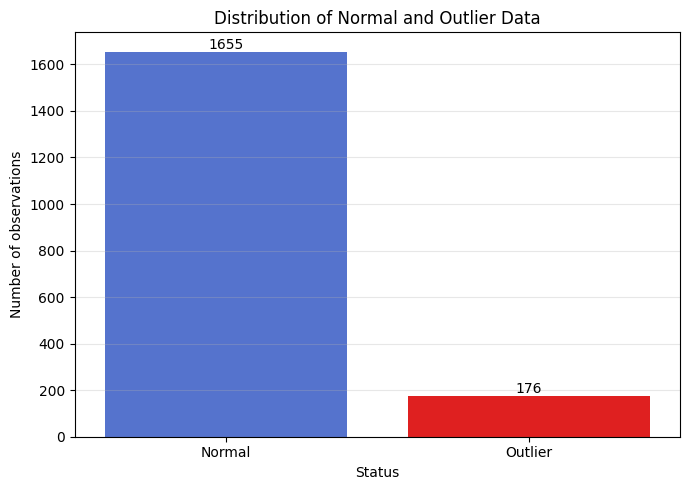

In [ ]:
# =========================================================
# 2. 정상 및 이상치 데이터 개수 시각화
# =========================================================
status_counts = (
    visualization_df["status"]
    .value_counts()
    .reindex(["Normal", "Outlier"])
)

plt.figure(figsize=(7, 5))

ax = sns.barplot(
    x=status_counts.index,
    y=status_counts.values,
    hue=status_counts.index,
    palette={
        "Normal": "royalblue",
        "Outlier": "red"
    },
    legend=False
)

# 막대 위에 데이터 개수 표시
for container in ax.containers:
    ax.bar_label(container, fmt="%d")

plt.xlabel("Status")
plt.ylabel("Number of observations")
plt.title("Distribution of Normal and Outlier Data")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
print("클래스별 데이터 개수")
print(status_counts)

print("\n클래스별 데이터 비율")
print(
    visualization_df["status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)


클래스별 데이터 개수
status
Normal     1655
Outlier     176
Name: count, dtype: int64

클래스별 데이터 비율
status
Normal     90.39
Outlier     9.61
Name: proportion, dtype: float64


전체 변수 상관계수
             LB     AC     FM     UC     DL     DS     DP   ASTV   MSTV  \
LB        1.000  0.027 -0.017 -0.086 -0.109 -0.051 -0.081  0.226 -0.208   
AC        0.027  1.000  0.043  0.007 -0.180 -0.053 -0.157 -0.197  0.126   
FM       -0.017  0.043  1.000 -0.083  0.032 -0.012  0.264 -0.085  0.109   
UC       -0.086  0.007 -0.083  1.000  0.257  0.001  0.054 -0.125  0.217   
DL       -0.109 -0.180  0.032  0.257  1.000  0.107  0.206 -0.041  0.530   
DS       -0.051 -0.053 -0.012  0.001  0.107  1.000  0.012  0.047  0.030   
DP       -0.081 -0.157  0.264  0.054  0.206  0.012  1.000  0.106  0.244   
ASTV      0.226 -0.197 -0.085 -0.125 -0.041  0.047  0.106  1.000 -0.337   
MSTV     -0.208  0.126  0.109  0.217  0.530  0.030  0.244 -0.337  1.000   
ALTV      0.188 -0.311 -0.068 -0.216 -0.226 -0.026 -0.115  0.363 -0.398   
MLTV     -0.038 -0.159  0.002 -0.082 -0.262 -0.039 -0.241 -0.338  0.056   
Width    -0.083  0.266  0.161  0.088  0.506  0.044  0.251 -0.186  0.646   
Min       0.30

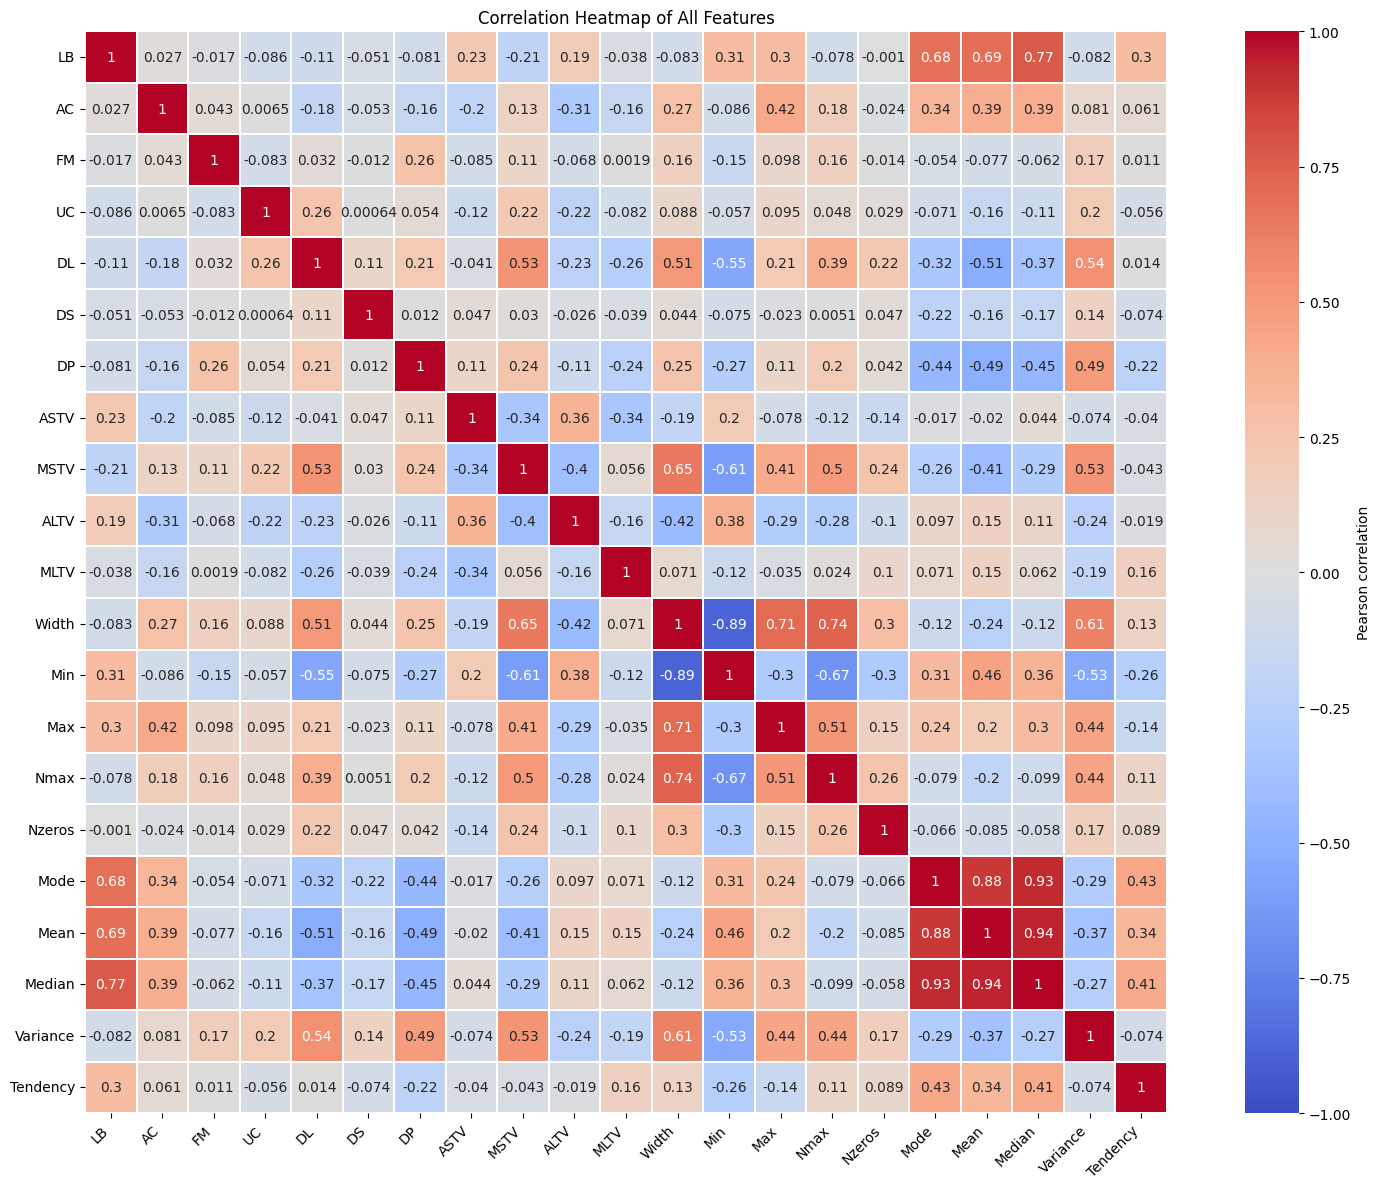

In [ ]:
# =========================================================
# 3. 전체 입력 변수 상관관계 계산
# =========================================================
feature_correlation = X.corr(method="pearson")

print("전체 변수 상관계수")
print(feature_correlation.round(3))

# =========================================================
# 4. 전체 입력 변수 상관관계 히트맵
# =========================================================
plt.figure(figsize=(16, 12))

sns.heatmap(
    feature_correlation,
    annot=True,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.3,
    cbar_kws={
        "label": "Pearson correlation"
    }
)

plt.title("Correlation Heatmap of All Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()



이상치 여부와 각 변수의 상관관계
DP          0.5904
Mode       -0.4192
Mean       -0.4165
ASTV        0.3894
Median     -0.3843
Variance    0.3275
ALTV        0.3267
AC         -0.2680
MLTV       -0.2568
Tendency   -0.2003
DL          0.1658
DS          0.1599
FM          0.1101
UC         -0.1025
Min        -0.0746
MSTV        0.0495
Width       0.0386
Max        -0.0350
Nmax        0.0284
LB         -0.0092
Nzeros      0.0048
Name: is_outlier, dtype: float64


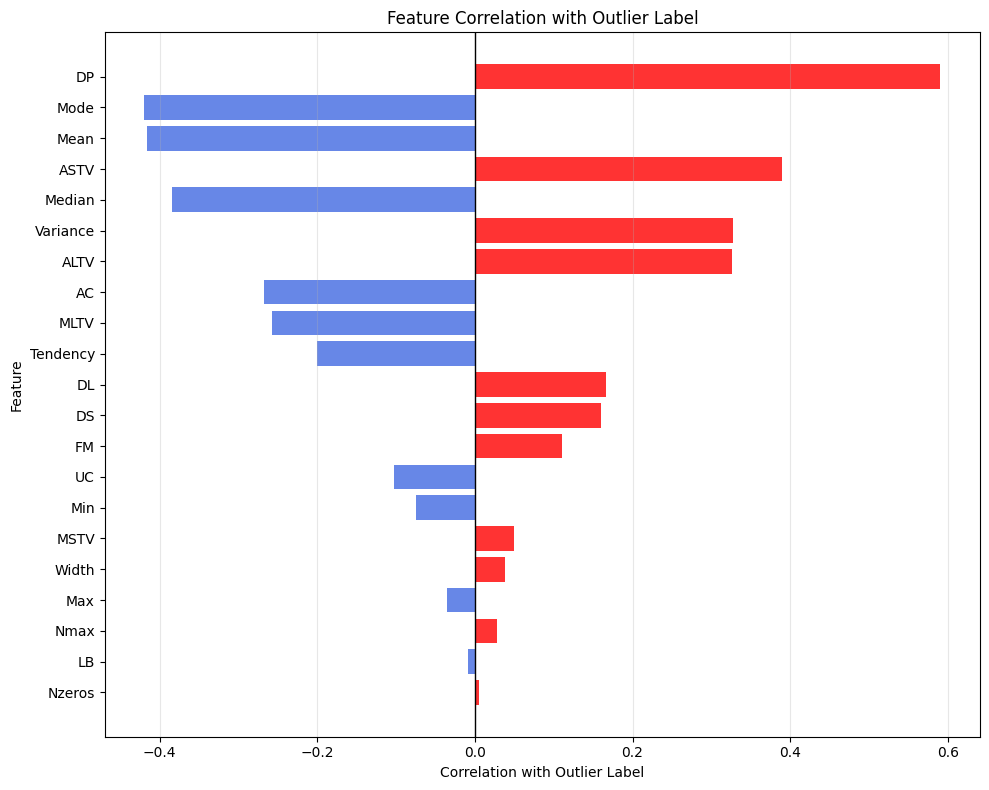

In [ ]:
# =========================================================
# 5. 이상치 여부와 각 변수의 상관관계 계산
# =========================================================
target_correlation = (
    visualization_df[
        list(X.columns) + ["is_outlier"]
    ]
    .corr(method="pearson")["is_outlier"]
    .drop("is_outlier")
    .sort_values(
        key=lambda values: values.abs(),
        ascending=False
    )
)

print("이상치 여부와 각 변수의 상관관계")
print(target_correlation.round(4))


# =========================================================
# 6. 이상치 여부와 변수 간 상관관계 시각화
# =========================================================
plt.figure(figsize=(10, 8))

correlation_colors = [
    "red" if value > 0 else "royalblue"
    for value in target_correlation.values
]

plt.barh(
    target_correlation.index,
    target_correlation.values,
    color=correlation_colors,
    alpha=0.8
)

plt.axvline(
    x=0,
    color="black",
    linewidth=1
)

plt.xlabel("Correlation with Outlier Label")
plt.ylabel("Feature")
plt.title("Feature Correlation with Outlier Label")
plt.grid(axis="x", alpha=0.3)
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [ ]:
# =========================================================
# 7. 주요 변수 자동 선정
# =========================================================
number_of_top_features = 6

top_features = (
    target_correlation
    .abs()
    .nlargest(number_of_top_features)
    .index
    .tolist()
)

print("선정된 주요 변수")
for rank, feature in enumerate(top_features, start=1):
    correlation_value = target_correlation[feature]

    print(
        f"{rank}. {feature}: "
        f"correlation={correlation_value:.4f}"
    )


선정된 주요 변수
1. DP: correlation=0.5904
2. Mode: correlation=-0.4192
3. Mean: correlation=-0.4165
4. ASTV: correlation=0.3894
5. Median: correlation=-0.3843
6. Variance: correlation=0.3275


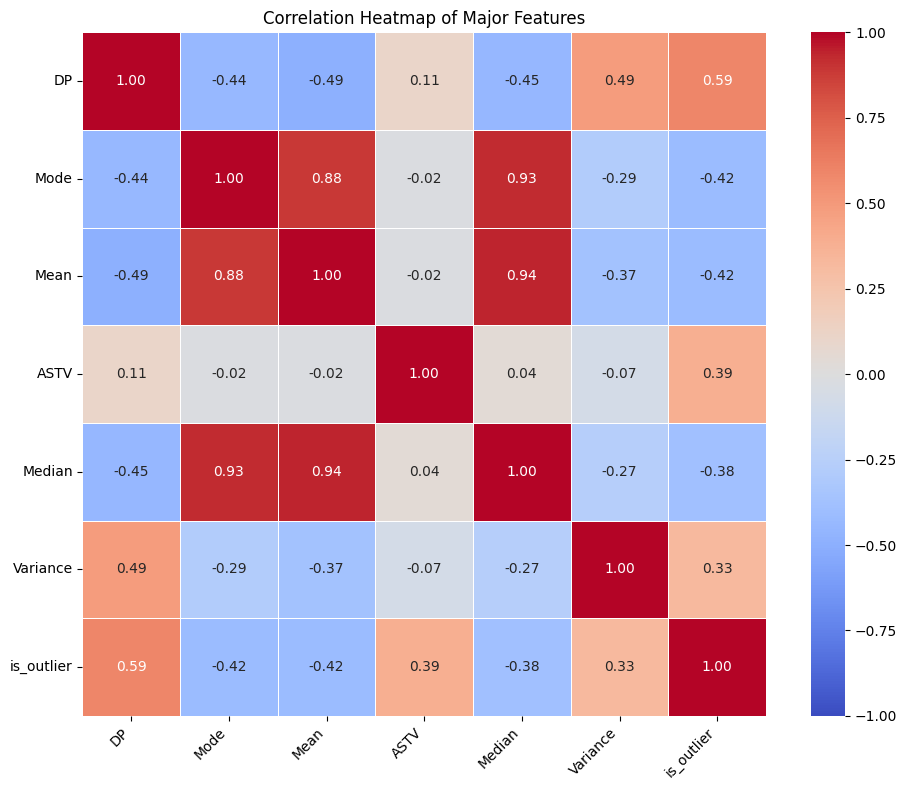

In [ ]:
# =========================================================
# 8. 주요 변수 상관관계 히트맵
# =========================================================
top_correlation_columns = (
    top_features + ["is_outlier"]
)

top_correlation = visualization_df[
    top_correlation_columns
].corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    top_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title("Correlation Heatmap of Major Features")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()


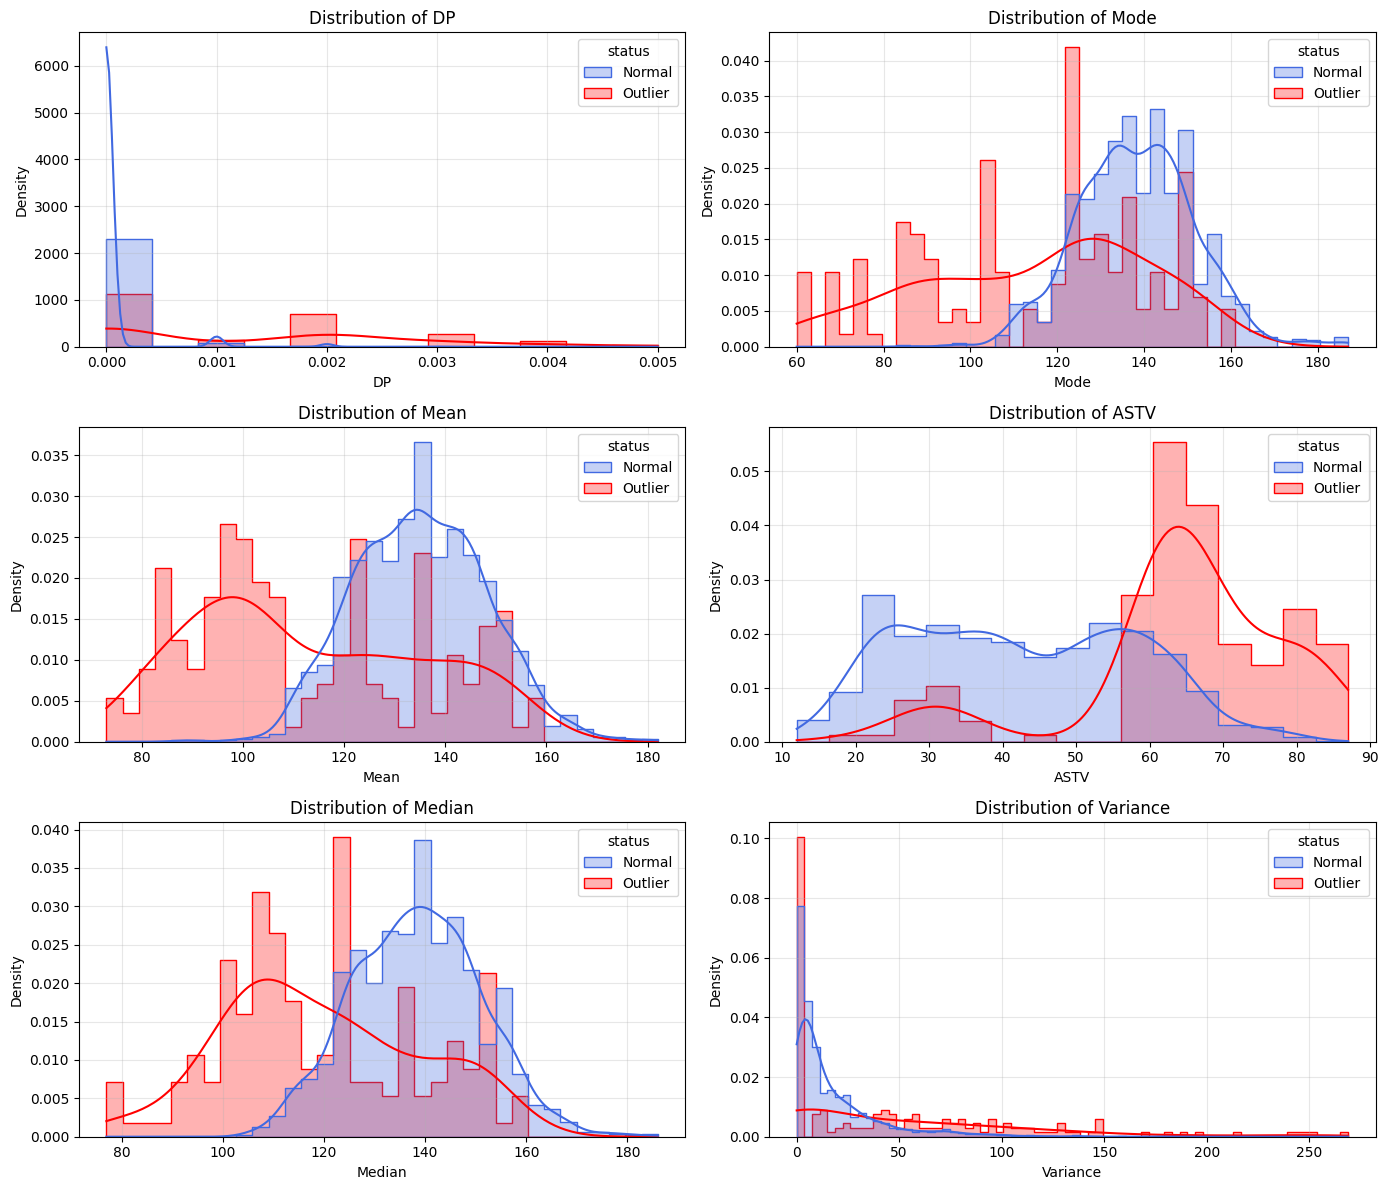

In [ ]:
# =========================================================
# 10. 주요 변수별 분포 시각화
# =========================================================
number_of_features = len(top_features)
number_of_columns = 2
number_of_rows = int(
    np.ceil(number_of_features / number_of_columns)
)

fig, axes = plt.subplots(
    number_of_rows,
    number_of_columns,
    figsize=(14, 4 * number_of_rows)
)

axes = np.array(axes).reshape(-1)

for index, feature in enumerate(top_features):
    sns.histplot(
        data=visualization_df,
        x=feature,
        hue="status",
        hue_order=["Normal", "Outlier"],
        palette={
            "Normal": "royalblue",
            "Outlier": "red"
        },
        kde=True,
        element="step",
        stat="density",
        common_norm=False,
        alpha=0.3,
        ax=axes[index]
    )

    axes[index].set_title(
        f"Distribution of {feature}"
    )

    axes[index].grid(alpha=0.3)

# 사용하지 않는 축 제거
for index in range(
    number_of_features,
    len(axes)
):
    fig.delaxes(axes[index])

plt.tight_layout()
plt.show()


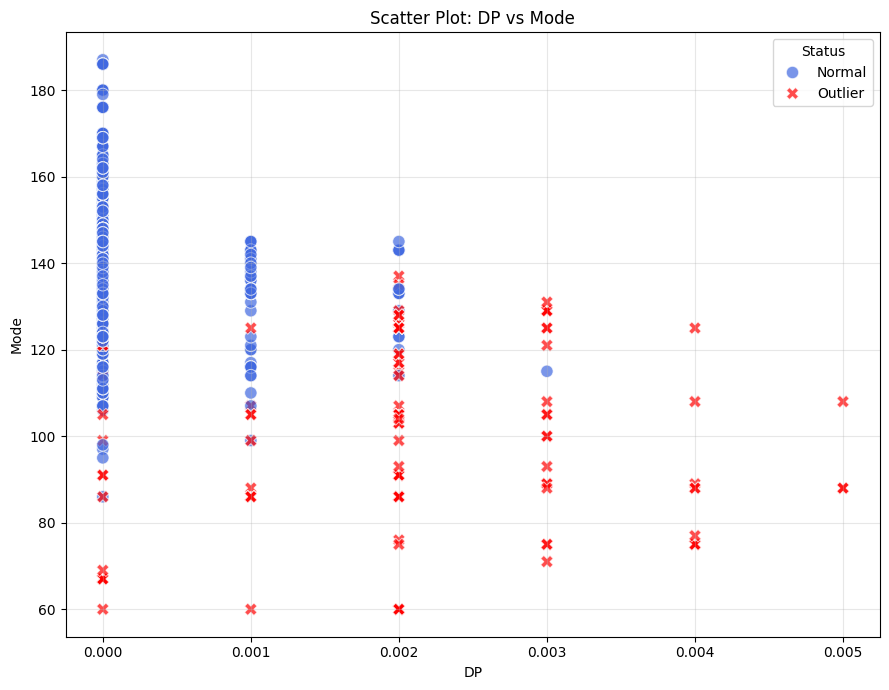

In [ ]:
# =========================================================
# 11. 상위 두 변수 산점도
# =========================================================
feature_x = top_features[0]
feature_y = top_features[1]

plt.figure(figsize=(9, 7))

sns.scatterplot(
    data=visualization_df,
    x=feature_x,
    y=feature_y,
    hue="status",
    hue_order=["Normal", "Outlier"],
    style="status",
    palette={
        "Normal": "royalblue",
        "Outlier": "red"
    },
    s=80,
    alpha=0.7
)

plt.xlabel(feature_x)
plt.ylabel(feature_y)

plt.title(
    f"Scatter Plot: {feature_x} vs {feature_y}"
)

plt.grid(alpha=0.3)
plt.legend(title="Status")
plt.tight_layout()
plt.show()


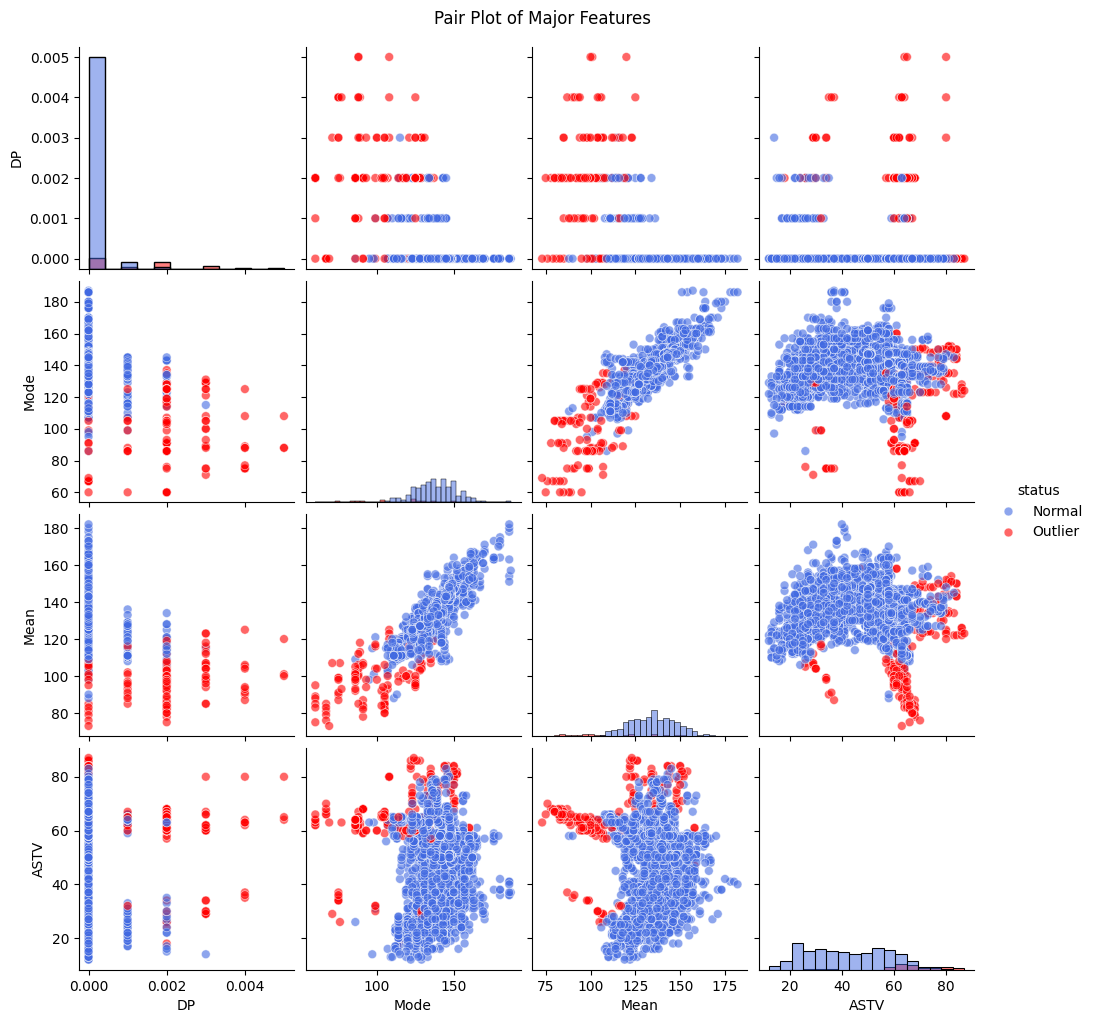

In [ ]:
# =========================================================
# 11. 주요 변수 Pair Plot
# =========================================================
pairplot_features = top_features[:4]

pairplot_df = visualization_df[
    pairplot_features + ["status"]
].copy()

sns.pairplot(
    data=pairplot_df,
    vars=pairplot_features,
    hue="status",
    hue_order=["Normal", "Outlier"],
    palette={
        "Normal": "royalblue",
        "Outlier": "red"
    },
    diag_kind="hist",
    plot_kws={
        "alpha": 0.6,
        "s": 40
    }
)

plt.suptitle(
    "Pair Plot of Major Features",
    y=1.02
)

plt.show()


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from numpy.linalg import pinv

from sklearn.ensemble import IsolationForest
from sklearn.svm import OneClassSVM
from sklearn.neighbors import LocalOutlierFactor
from sklearn.decomposition import PCA

from sklearn.metrics import (
    confusion_matrix,
    precision_score,
    recall_score,
    f1_score,
    accuracy_score,
    roc_auc_score,
    average_precision_score
)


## Mahalanobis Distance

X: 원본 입력 변수
X_scaled: 표준화된 입력 변수
y_true: 실제 이상치 정답

In [ ]:
# =========================================================
# 1. 분석용 데이터 준비
# =========================================================
X_original = X.copy().reset_index(drop=True)
X_model = X_scaled.copy().reset_index(drop=True)

y_actual = (
    y_true
    .copy()
    .reset_index(drop=True)
    .astype(int)
)

# 모든 모델에서 사용할 예상 이상치 비율
contamination = 0.10

print(f"전체 데이터 개수: {len(X_model)}")
print(f"입력 변수 개수: {X_model.shape[1]}")
print(f"실제 정상 개수: {(y_actual == 0).sum()}")
print(f"실제 이상치 개수: {(y_actual == 1).sum()}")
print(f"실제 이상치 비율: {y_actual.mean():.4f}")


전체 데이터 개수: 1831
입력 변수 개수: 21
실제 정상 개수: 1655
실제 이상치 개수: 176
실제 이상치 비율: 0.0961


In [ ]:
# =========================================================
# 2. 결과 저장용 데이터프레임
# =========================================================
result_df = X_original.copy()

result_df["actual_outlier"] = y_actual


In [ ]:
# =========================================================
# 3. Mahalanobis Distance
# =========================================================
X_array = X_model.to_numpy()

# 평균 벡터
mean_vector = np.mean(
    X_array,
    axis=0
)

# 공분산 행렬
cov_matrix = np.cov(
    X_array,
    rowvar=False
)

# 공분산 행렬의 유사역행렬
inv_cov_matrix = pinv(
    cov_matrix
)

# 평균과 각 데이터의 차이
difference = X_array - mean_vector

# Mahalanobis 거리의 제곱
mahalanobis_squared = np.einsum(
    "ij,jk,ik->i",
    difference,
    inv_cov_matrix,
    difference
)

# 부동소수점 계산으로 생길 수 있는 음수 제거
mahalanobis_squared = np.maximum(
    mahalanobis_squared,
    0
)

# Mahalanobis 거리
mahalanobis_score = np.sqrt(
    mahalanobis_squared
)

# 상위 10%를 이상치로 설정
mahalanobis_threshold = np.quantile(
    mahalanobis_score,
    1 - contamination
)

mahalanobis_prediction = (
    mahalanobis_score > mahalanobis_threshold
).astype(int)

# 결과 저장
result_df["md_score"] = mahalanobis_score
result_df["md_outlier"] = mahalanobis_prediction

print(
    "Mahalanobis 임계값:",
    round(mahalanobis_threshold, 4)
)

print(
    "Mahalanobis 이상치 개수:",
    mahalanobis_prediction.sum()
)


Mahalanobis 임계값: 6.0019
Mahalanobis 이상치 개수: 183


## Local Outlier Factor

In [ ]:
# =========================================================
# Local Outlier Factor
# =========================================================
lof_model = LocalOutlierFactor(
    n_neighbors=20,
    contamination=contamination,
    metric="minkowski",
    p=2
)

lof_original_prediction = (
    lof_model.fit_predict(X_model)
)

# 원래 결과:
#  1: 정상
# -1: 이상치
lof_prediction = (
    lof_original_prediction == -1
).astype(int)

# negative_outlier_factor_는 작을수록 이상치
# 부호를 바꿔 값이 클수록 이상치가 되도록 통일
lof_anomaly_score = (
    -lof_model.negative_outlier_factor_
)

# 결과 저장
result_df["lof_score"] = lof_anomaly_score
result_df["lof_outlier"] = lof_prediction

print(
    "LOF 이상치 개수:",
    lof_prediction.sum()
)


LOF 이상치 개수: 183


## One-Class SVM

In [ ]:
# =========================================================
# One-Class SVM
# =========================================================
ocsvm_model = OneClassSVM(
    kernel="rbf",
    gamma="scale",
    nu=contamination
)

ocsvm_original_prediction = (
    ocsvm_model.fit_predict(X_model)
)

# 원래 결과:
#  1: 정상
# -1: 이상치
ocsvm_prediction = (
    ocsvm_original_prediction == -1
).astype(int)

# decision_function 값은 작을수록 이상치
# 부호를 바꿔 값이 클수록 이상치가 되도록 통일
ocsvm_anomaly_score = -ocsvm_model.decision_function(
    X_model
)

# 결과 저장
result_df["ocsvm_score"] = ocsvm_anomaly_score
result_df["ocsvm_outlier"] = ocsvm_prediction

print(
    "One-Class SVM 이상치 개수:",
    ocsvm_prediction.sum()
)


One-Class SVM 이상치 개수: 180


## Isolation Forest

In [ ]:
# =========================================================
# Isolation Forest
# =========================================================
isolation_forest_model = IsolationForest(
    n_estimators=200,
    contamination=contamination,
    random_state=0,
    n_jobs=-1
)

if_original_prediction = (
    isolation_forest_model.fit_predict(X_model)
)

# 원래 결과:
#  1: 정상
# -1: 이상치
if_prediction = (
    if_original_prediction == -1
).astype(int)

# decision_function 값은 작을수록 이상치
# 부호를 반대로 바꿔 값이 클수록 이상치가 되도록 통일
if_anomaly_score = -isolation_forest_model.decision_function(
    X_model
)

# 결과 저장
result_df["if_score"] = if_anomaly_score
result_df["if_outlier"] = if_prediction

print(
    "Isolation Forest 이상치 개수:",
    if_prediction.sum()
)


Isolation Forest 이상치 개수: 183


## 모델별 결과 비교

In [ ]:
# =========================================================
# 모델별 예측 결과 요약
# =========================================================
prediction_columns = [
    "actual_outlier",
    "md_outlier",
    "if_outlier",
    "ocsvm_outlier",
    "lof_outlier"
]

score_columns = [
    "md_score",
    "if_score",
    "ocsvm_score",
    "lof_score"
]

print("\n모델별 이상치 탐지 개수")

for column in prediction_columns:
    print(
        f"{column}: "
        f"{result_df[column].sum()}"
    )



모델별 이상치 탐지 개수
actual_outlier: 176
md_outlier: 183
if_outlier: 183
ocsvm_outlier: 180
lof_outlier: 183


In [ ]:
# =========================================================
# 모델별 성능 평가 함수
# =========================================================
def evaluate_outlier_model(
    y_true,
    y_pred,
    anomaly_score,
    model_name
):
    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    precision = precision_score(
        y_true,
        y_pred,
        zero_division=0
    )

    recall = recall_score(
        y_true,
        y_pred,
        zero_division=0
    )

    f1 = f1_score(
        y_true,
        y_pred,
        zero_division=0
    )

    roc_auc = roc_auc_score(
        y_true,
        anomaly_score
    )

    pr_auc = average_precision_score(
        y_true,
        anomaly_score
    )

    return {
        "Model": model_name,
        "Detected Outliers": int(np.sum(y_pred)),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1,
        "ROC-AUC": roc_auc,
        "PR-AUC": pr_auc
    }


In [ ]:
# =========================================================
# 모델별 평가 실행
# =========================================================
evaluation_results = []

evaluation_results.append(
    evaluate_outlier_model(
        y_true=y_actual,
        y_pred=result_df["md_outlier"],
        anomaly_score=result_df["md_score"],
        model_name="Mahalanobis"
    )
)

evaluation_results.append(
    evaluate_outlier_model(
        y_true=y_actual,
        y_pred=result_df["if_outlier"],
        anomaly_score=result_df["if_score"],
        model_name="Isolation Forest"
    )
)

evaluation_results.append(
    evaluate_outlier_model(
        y_true=y_actual,
        y_pred=result_df["ocsvm_outlier"],
        anomaly_score=result_df["ocsvm_score"],
        model_name="One-Class SVM"
    )
)

evaluation_results.append(
    evaluate_outlier_model(
        y_true=y_actual,
        y_pred=result_df["lof_outlier"],
        anomaly_score=result_df["lof_score"],
        model_name="LOF"
    )
)

evaluation_df = pd.DataFrame(
    evaluation_results
)

evaluation_df = evaluation_df.set_index(
    "Model"
)

print("\n모델별 성능 평가 결과")
print(evaluation_df.round(4))



모델별 성능 평가 결과
                  Detected Outliers  Accuracy  Precision  Recall  F1-Score  \
Model                                                                        
Mahalanobis                     183    0.8924     0.4426  0.4602    0.4513   
Isolation Forest                183    0.9044     0.5027  0.5227    0.5125   
One-Class SVM                   180    0.8831     0.3944  0.4034    0.3989   
LOF                             183    0.8400     0.1803  0.1875    0.1838   

                  ROC-AUC  PR-AUC  
Model                              
Mahalanobis        0.8965  0.4550  
Isolation Forest   0.9355  0.5834  
One-Class SVM      0.8730  0.4052  
LOF                0.5509  0.1547  


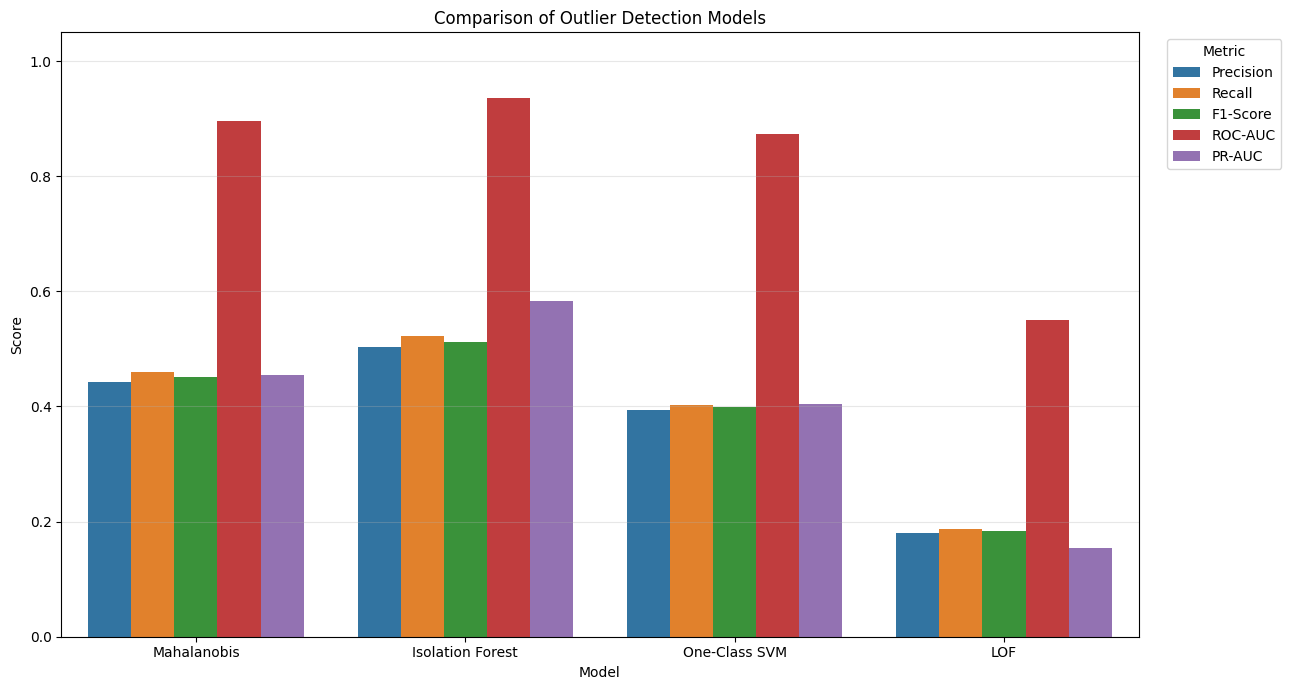

In [ ]:
# =========================================================
# 성능지표 비교 시각화
# =========================================================
metric_columns = [
    "Precision",
    "Recall",
    "F1-Score",
    "ROC-AUC",
    "PR-AUC"
]

evaluation_plot_df = (
    evaluation_df[metric_columns]
    .reset_index()
    .melt(
        id_vars="Model",
        var_name="Metric",
        value_name="Score"
    )
)

plt.figure(figsize=(13, 7))

sns.barplot(
    data=evaluation_plot_df,
    x="Model",
    y="Score",
    hue="Metric"
)

plt.ylim(0, 1.05)
plt.xlabel("Model")
plt.ylabel("Score")
plt.title("Comparison of Outlier Detection Models")
plt.legend(
    title="Metric",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
